# Building an Image Classifier with CNNs

## Étape 1 : Introduction au CNN

### Qu'est-ce qu'un CNN ?
Un **réseau de neurones convolutif** (CNN) est un réseau de neurones conçu pour traiter des données en grille, typiquement des images. Au lieu de relier chaque pixel à chaque neurone (ce qui donnerait un nombre énorme de paramètres), un CNN fait glisser de petits **filtres** sur l'image pour détecter des motifs locaux (bords, textures, formes). Les premières couches détectent des motifs simples (contours), les couches profondes les combinent en motifs complexes (oreilles, museau, yeux).

Deux idées clés :
- **Connexions locales** : chaque neurone ne regarde qu'une petite région de l'image.
- **Partage des poids** : le même filtre est appliqué partout dans l'image, donc un motif est reconnu quelle que soit sa position, et le nombre de paramètres reste faible.

### Composants principaux

**Couche convolutive (`Conv2D`)** : applique $K$ filtres de taille $k \times k$ sur l'entrée. Chaque filtre produit une *carte de caractéristiques* (feature map). Nombre de paramètres d'une couche :
$$(k \times k \times C_{in} + 1) \times K$$
où $C_{in}$ est le nombre de canaux d'entrée et le $+1$ correspond au biais.

**Fonction d'activation (ReLU)** : $f(x) = \max(0, x)$. Elle introduit de la non-linéarité (sans elle, empiler des couches équivaudrait à une seule transformation linéaire). Elle est simple, rapide à calculer et limite le problème de disparition du gradient.

**Couche de pooling (`MaxPooling2D`)** : réduit la taille spatiale (ici de moitié avec une fenêtre 2×2) en gardant le maximum de chaque fenêtre. Cela diminue le nombre de calculs, apporte une petite invariance aux translations et réduit le risque de surapprentissage. Elle n'a **aucun paramètre**.

**Couche entièrement connectée (`Dense`)** : après `Flatten`, chaque neurone est relié à toutes les entrées. Elle combine les caractéristiques extraites pour décider. Paramètres : $(n_{in} + 1) \times n_{out}$.

**Sortie sigmoïde** : pour une classification binaire (chat / chien), un seul neurone avec activation sigmoïde $\sigma(x) = \frac{1}{1+e^{-x}}$ donne une probabilité entre 0 et 1.

## Configuration

In [1]:
import os, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Reproductibilité
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow :", tf.__version__)
print("GPU détecté :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.22.0-rc0
GPU détecté : []


## Étape 2 : Exploration du jeu de données

On utilise le jeu `cats_and_dogs_filtered` (sous-ensemble du dataset Kaggle *Dogs vs Cats*), qui contient déjà un dossier `train` et un dossier `validation`.

### Load the dataset

In [2]:
import os

# Chemin relatif vers le dossier
BASE_DIR = "cats_and_dogs_filtered"
TRAIN_DIR = os.path.join(BASE_DIR, "train")
VAL_DIR = os.path.join(BASE_DIR, "validation")

# Vérification de l'existence des répertoires
assert os.path.isdir(TRAIN_DIR) and os.path.isdir(VAL_DIR), "Vérifiez la structure du dossier cats_and_dogs_filtered"
print("Classes dans train :", sorted(os.listdir(TRAIN_DIR)))

Classes dans train : ['cats', 'dogs']


### Combien d'images de chats et de chiens y a-t-il ?

In [3]:
def count_images(directory):
    counts = {}
    for cls in sorted(os.listdir(directory)):
        cls_path = os.path.join(directory, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len([f for f in os.listdir(cls_path)
                               if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    return counts

train_counts = count_images(TRAIN_DIR)
val_counts = count_images(VAL_DIR)

df_counts = pd.DataFrame({"train": train_counts, "validation": val_counts})
df_counts.loc["total"] = df_counts.sum()
print(df_counts)

       train  validation
cats    1000         500
dogs    1000         500
total   2000        1000


### Distribution des classes et forme des entrées

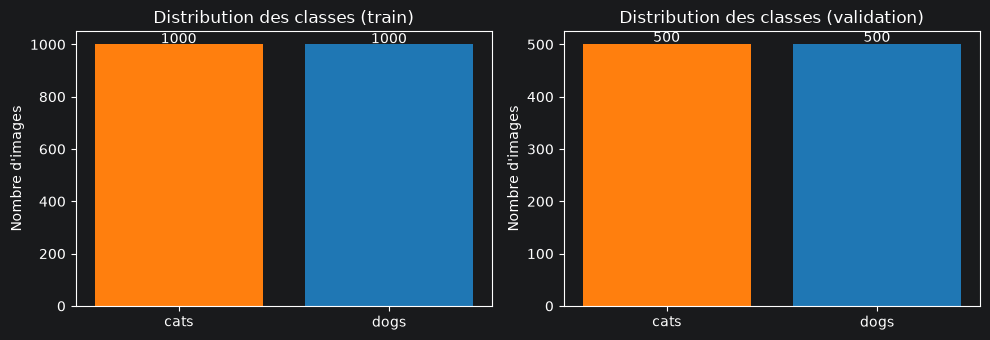

Exemples de tailles brutes (H, W, canaux) : [(89, 105, 3), (113, 149, 3), (116, 180, 3), (119, 80, 3), (129, 153, 3)] ...
Nombre de tailles différentes sur 200 images : 146

On redimensionne toutes les images en 150x150 -> forme d'entrée du modèle : (150, 150, 3)


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (name, counts) in zip(axes, [("train", train_counts), ("validation", val_counts)]):
    ax.bar(counts.keys(), counts.values(), color=["tab:orange", "tab:blue"])
    ax.set_title(f"Distribution des classes ({name})")
    ax.set_ylabel("Nombre d'images")
    for i, v in enumerate(counts.values()):
        ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout()
plt.show()

# Forme des images brutes (les tailles varient d'une image à l'autre)
sample_dir = os.path.join(TRAIN_DIR, "cats")
shapes = [np.array(load_img(os.path.join(sample_dir, f))).shape
          for f in sorted(os.listdir(sample_dir))[:200]]
print("Exemples de tailles brutes (H, W, canaux) :", sorted(set(shapes))[:5], "...")
print("Nombre de tailles différentes sur 200 images :", len(set(shapes)))

IMG_SIZE = 150
print(f"\nOn redimensionne toutes les images en {IMG_SIZE}x{IMG_SIZE} -> forme d'entrée du modèle : ({IMG_SIZE}, {IMG_SIZE}, 3)")

**Analyse :** les classes sont équilibrées (autant de chats que de chiens), donc l'accuracy est une métrique pertinente et il n'y a pas besoin de pondérer les classes. Les images brutes ont des tailles variables, il faut donc les redimensionner à une taille fixe pour alimenter le réseau, et normaliser les pixels de $[0, 255]$ vers $[0, 1]$.

### Visualisation de quelques images

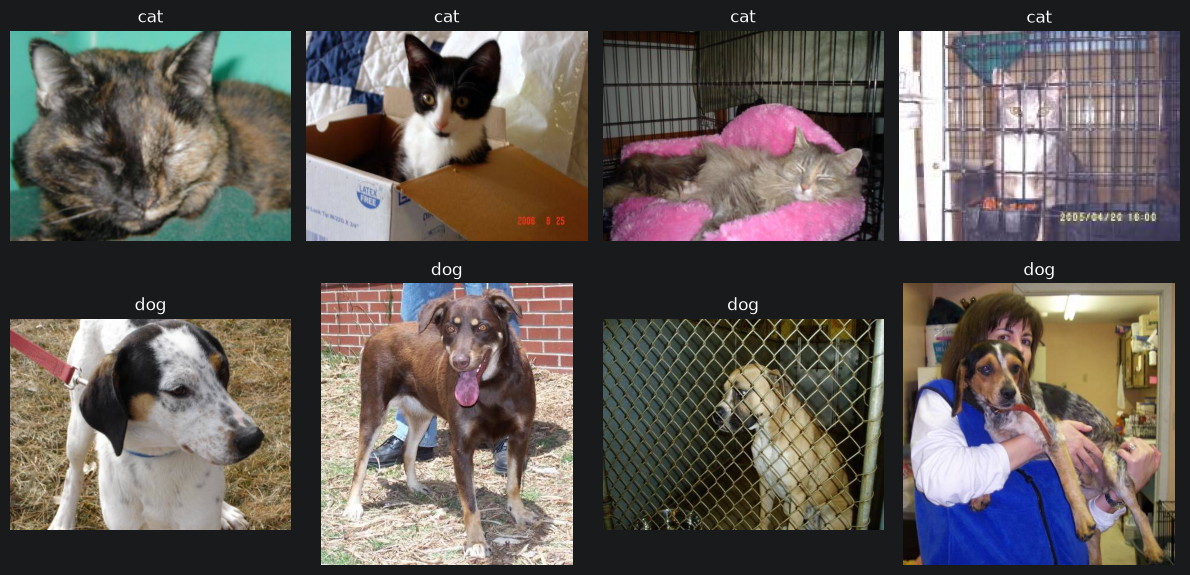

In [5]:
def show_samples(directory, n=4):
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6))
    for row, cls in enumerate(["cats", "dogs"]):
        cls_path = os.path.join(directory, cls)
        files = random.sample(sorted(os.listdir(cls_path)), n)
        for col, f in enumerate(files):
            img = load_img(os.path.join(cls_path, f))
            axes[row, col].imshow(img)
            axes[row, col].set_title(cls[:-1])   # cat / dog
            axes[row, col].axis("off")
    plt.tight_layout()
    plt.show()

show_samples(TRAIN_DIR)

### Séparation du jeu d'entraînement en train / test (80 % - 20 %)

In [6]:
# Dossier local de destination des images split
SPLIT_DIR = "data_split"

# Nettoie et recrée l'arborescence si le dossier existe déjà
if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

for split in ["train", "test"]:
    for cls in ["cats", "dogs"]:
        os.makedirs(os.path.join(SPLIT_DIR, split, cls), exist_ok=True)

# Récupération de toutes les images du dossier train existant
items = [(cls, f) for cls in ["cats", "dogs"]
         for f in sorted(os.listdir(os.path.join(TRAIN_DIR, cls)))
         if f.lower().endswith((".jpg", ".jpeg", ".png"))]

labels = [cls for cls, _ in items]

# Découpage stratifié 80 % / 20 %
train_items, test_items = train_test_split(
    items,
    test_size=0.2,
    stratify=labels,
    random_state=42
)

# Copie des fichiers vers la nouvelle arborescence
for dest, subset in [("train", train_items), ("test", test_items)]:
    for cls, f in subset:
        src_path = os.path.join(TRAIN_DIR, cls, f)
        dst_path = os.path.join(SPLIT_DIR, dest, cls, f)
        shutil.copy(src_path, dst_path)

NEW_TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
TEST_DIR = os.path.join(SPLIT_DIR, "test")

print("Train :", count_images(NEW_TRAIN_DIR))
print("Test  :", count_images(TEST_DIR))
print("Validation (dossier d'origine) :", count_images(VAL_DIR))

Train : {'cats': 800, 'dogs': 800}
Test  : {'cats': 200, 'dogs': 200}
Validation (dossier d'origine) : {'cats': 500, 'dogs': 500}


## Étape 3 : Construction du CNN

Architecture : **4 blocs convolutifs** (Conv2D 3×3 + ReLU, puis MaxPooling 2×2) avec 32, 64, 128 et 128 filtres, suivis d'un `Flatten`, d'une couche `Dense(512, relu)` et d'une couche de sortie `Dense(1, sigmoid)`.

In [7]:
def build_baseline(img_size=150):
    model = models.Sequential([
        layers.Input(shape=(img_size, img_size, 3)),
        # Bloc 1
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        # Bloc 2
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        # Bloc 3
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        # Bloc 4
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        # Classifieur
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dense(1, activation="sigmoid"),   # probabilité d'être un chien
    ])
    return model

model = build_baseline(IMG_SIZE)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

### Compilation du modèle

In [8]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss="binary_crossentropy",
              metrics=["accuracy"])

Justification du choix :
- **Fonction de perte : `binary_crossentropy`**. Le problème est une classification binaire avec une sortie sigmoïde (probabilité). L'entropie croisée binaire pénalise fortement les prédictions confiantes mais fausses, et fournit un bon gradient pour la sigmoïde.
- **Optimiseur : `Adam`**. Il adapte le pas d'apprentissage pour chaque paramètre (combine momentum et RMSprop), converge rapidement avec peu de réglages et marche bien par défaut sur les CNN (lr = 1e-3).
- **Métrique : `accuracy`**, pertinente car les classes sont équilibrées.

### Nombre total de paramètre et calcul

**Formules :**
- Conv2D : $(k \times k \times C_{in} + 1) \times K$
- Dense : $(n_{in} + 1) \times n_{out}$
- MaxPooling et Flatten : 0 paramètre

**Évolution de la taille spatiale** (convolution 3×3 sans padding : $n \to n-2$, puis pooling : $n \to \lfloor n/2 \rfloor$) :

$150 \to 148 \to 74 \to 72 \to 36 \to 34 \to 17 \to 15 \to 7$

Après le bloc 4 la carte est de taille $7 \times 7 \times 128$, donc `Flatten` donne $7 \times 7 \times 128 = 6272$ valeurs.

| Couche | Calcul | Paramètres |
|---|---|---|
| Conv2D 1 (3 → 32) | $(3\times3\times3+1)\times32$ | 896 |
| Conv2D 2 (32 → 64) | $(3\times3\times32+1)\times64$ | 18 496 |
| Conv2D 3 (64 → 128) | $(3\times3\times64+1)\times128$ | 73 856 |
| Conv2D 4 (128 → 128) | $(3\times3\times128+1)\times128$ | 147 584 |
| Dense 512 | $(6272+1)\times512$ | 3 211 776 |
| Dense 1 (sortie) | $(512+1)\times1$ | 513 |
| **Total** | | **3 453 121** |



Vérification par le code :

In [9]:
def conv_params(k, c_in, n_filters):
    return (k * k * c_in + 1) * n_filters

def dense_params(n_in, n_out):
    return (n_in + 1) * n_out

p1 = conv_params(3, 3, 32)
p2 = conv_params(3, 32, 64)
p3 = conv_params(3, 64, 128)
p4 = conv_params(3, 128, 128)
flat = 7 * 7 * 128
p5 = dense_params(flat, 512)
p6 = dense_params(512, 1)

total_manual = p1 + p2 + p3 + p4 + p5 + p6
print(f"Conv1 {p1} | Conv2 {p2} | Conv3 {p3} | Conv4 {p4} | Dense512 {p5} | Sortie {p6}")
print("Total calculé à la main :", total_manual)
print("Total Keras (model.count_params()) :", model.count_params())
assert total_manual == model.count_params()

Conv1 896 | Conv2 18496 | Conv3 73856 | Conv4 147584 | Dense512 3211776 | Sortie 513
Total calculé à la main : 3453121
Total Keras (model.count_params()) : 3453121


## Étape 4 : Entraînement du CNN

### Chargement des données avec ImageDataGenerator

In [15]:
BATCH_SIZE = 100
IMG_SHAPE = (150, 150)

# Normalisation des pixels [0, 255] -> [0, 1]
train_image_generator = ImageDataGenerator(rescale=1./255)
val_image_generator   = ImageDataGenerator(rescale=1./255)
test_image_generator  = ImageDataGenerator(rescale=1./255)

# Générateur d'entraînement
train_data_gen = train_image_generator.flow_from_directory(
    batch_size=BATCH_SIZE,
    directory=NEW_TRAIN_DIR,
    shuffle=True,
    target_size=IMG_SHAPE,
    class_mode='binary'
)

# Générateur de validation (suivi pendant l'entraînement)
val_data_gen = val_image_generator.flow_from_directory(
    batch_size=BATCH_SIZE,
    directory=VAL_DIR,
    shuffle=False,
    target_size=IMG_SHAPE,
    class_mode='binary'
)

# Générateur de test (évaluation finale du modèle)
test_data_gen = test_image_generator.flow_from_directory(
    batch_size=BATCH_SIZE,
    directory=TEST_DIR,
    shuffle=False,
    target_size=IMG_SHAPE,
    class_mode='binary'
)

Found 1600 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Found 400 images belonging to 2 classes.


Entraînement sur **15 époques** avec un **batch de 100** (paramètre fixé dans `make_generators`).

In [12]:
EPOCHS = 15

history = model.fit(
    train_data_gen,
    epochs=EPOCHS,
    validation_data=val_data_gen
)

Epoch 1/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.4956 - loss: 0.7390 - val_accuracy: 0.5000 - val_loss: 0.6929
Epoch 2/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.5231 - loss: 0.6923 - val_accuracy: 0.4990 - val_loss: 0.6879
Epoch 3/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.5494 - loss: 0.6854 - val_accuracy: 0.5000 - val_loss: 0.7034
Epoch 4/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.5619 - loss: 0.6798 - val_accuracy: 0.6100 - val_loss: 0.6599
Epoch 5/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.6431 - loss: 0.6414 - val_accuracy: 0.6620 - val_loss: 0.6317
Epoch 6/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.6656 - loss: 0.6269 - val_accuracy: 0.6370 - val_loss: 0.6537
Epoch 7/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.6869 - loss: 0.5873 - val_accuracy: 0.6470 - val_loss: 0.6364
Epoch 8/15
16/16 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.7038 - loss: 0.5726 - val_accuracy: 0.6790 - val_loss:

### Courbes d'apprentissage

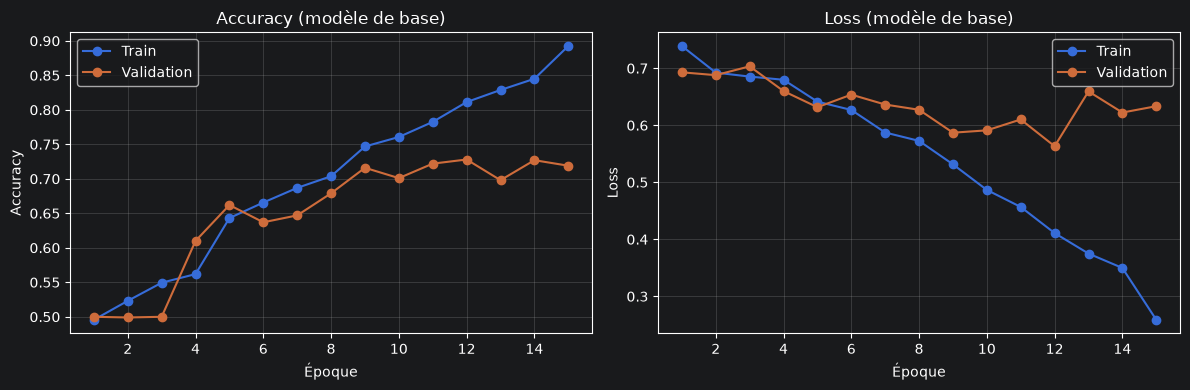

Accuracy finale  -> train : 0.892 | validation : 0.719
Loss finale      -> train : 0.259 | validation : 0.633


In [13]:
def plot_history(history, title=""):
    h = history.history
    epochs = range(1, len(h["accuracy"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, h["accuracy"], "o-", label="Train")
    axes[0].plot(epochs, h["val_accuracy"], "o-", label="Validation")
    axes[0].set_title(f"Accuracy {title}")
    axes[0].set_xlabel("Époque"); axes[0].set_ylabel("Accuracy"); axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, h["loss"], "o-", label="Train")
    axes[1].plot(epochs, h["val_loss"], "o-", label="Validation")
    axes[1].set_title(f"Loss {title}")
    axes[1].set_xlabel("Époque"); axes[1].set_ylabel("Loss"); axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history, "(modèle de base)")
print(f"Accuracy finale  -> train : {history.history['accuracy'][-1]:.3f} | validation : {history.history['val_accuracy'][-1]:.3f}")
print(f"Loss finale      -> train : {history.history['loss'][-1]:.3f} | validation : {history.history['val_loss'][-1]:.3f}")

### ✏️ À COMPLÉTER : surapprentissage ou sous-apprentissage ?



- L'accuracy d'entraînement est-elle bien supérieure à celle de validation ? À partir de quelle époque l'écart se creuse-t-il ?
- La loss de validation remonte-t-elle alors que la loss d'entraînement continue de baisser ? (signe typique de **surapprentissage**)
- Si les deux accuracy restaient basses, ce serait du **sous-apprentissage** (modèle trop simple ou entraînement trop court).
- Explication probable : ~3,4 millions de paramètres pour seulement 1 600 images d'entraînement, donc le réseau mémorise les images au lieu d'apprendre des caractéristiques générales.

*(Ce qu'on observe généralement sur ce dataset : train proche de 90-100 % et validation autour de 70-75 %, donc surapprentissage.)*

## Étape 5 : Évaluation du modèle

### Matrice de confusion

Un dictionnaire `results` collecte les métriques de chaque modèle pour les comparer à la fin.

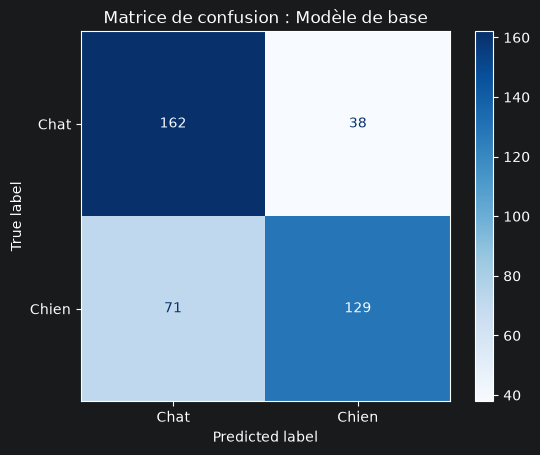

              precision    recall  f1-score   support

        Chat       0.70      0.81      0.75       200
       Chien       0.77      0.65      0.70       200

    accuracy                           0.73       400
   macro avg       0.73      0.73      0.73       400
weighted avg       0.73      0.73      0.73       400



,Accuracy,Precision,Recall,F1-score
Modèle de base,0.728,0.772,0.645,0.703


In [16]:
results = {}

def evaluate_model(model, test_gen, name):
    test_gen.reset()
    probs = model.predict(test_gen, verbose=0).ravel()
    y_pred = (probs > 0.5).astype(int)
    y_true = test_gen.classes   # shuffle=False -> même ordre que les prédictions

    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Chat", "Chien"])
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Matrice de confusion : {name}")
    plt.show()

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
    }
    print(classification_report(y_true, y_pred, target_names=["Chat", "Chien"]))
    results[name] = metrics
    return metrics

m_base = evaluate_model(model, test_data_gen, "Modèle de base")
pd.DataFrame(m_base, index=["Modèle de base"]).round(3)

**Rappel des métriques** (la classe « positive » est *Chien*) :
- **Accuracy** = (VP + VN) / total : proportion de bonnes prédictions.
- **Precision** = VP / (VP + FP) : quand le modèle dit « chien », à quelle fréquence a-t-il raison ?
- **Recall** = VP / (VP + FN) : parmi les vrais chiens, combien sont retrouvés ?
- **F1-score** = moyenne harmonique de la précision et du rappel.

On peut donc voir grâce à la matrice de confusion que notre modèle repère bien les chats (bon à 81%) mais à plus de mal avec les chiens (64.5%)



### ✏️ À COMPLÉTER : que peut-on dire du modèle ?
- Comparez l'accuracy de test à l'accuracy d'entraînement : confirme-t-elle le surapprentissage ?
- Lisez la matrice de confusion : le modèle confond-il plus souvent les chats pour des chiens ou l'inverse ? Precision et recall sont-ils équilibrés ?
- Les classes étant équilibrées, accuracy et F1 devraient être proches.

## Étape 6 : Améliorer le modèle

On applique chaque technique **séparément** (chacune est comparée au modèle de base), avec la même architecture, le même optimiseur et 15 époques pour une comparaison équitable.

### Data augmentation

Rotations, translations, cisaillement, zoom et symétrie horizontale appliqués **aléatoirement au jeu d'entraînement uniquement**. Le modèle voit ainsi des variantes différentes de chaque image à chaque époque, ce qui l'aide à généraliser. Validation et test restent non augmentés.

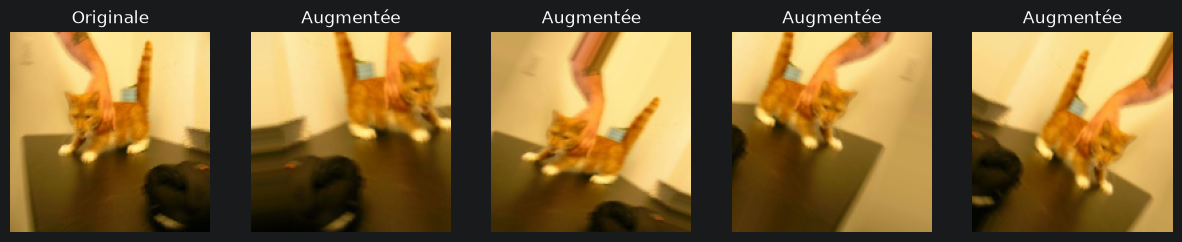

In [17]:
# Aperçu de l'augmentation sur une image
aug_preview = ImageDataGenerator(rotation_range=30, width_shift_range=0.2, height_shift_range=0.2,
                                 shear_range=0.2, zoom_range=0.2, horizontal_flip=True, fill_mode="nearest")
img_path = os.path.join(NEW_TRAIN_DIR, "cats", sorted(os.listdir(os.path.join(NEW_TRAIN_DIR, "cats")))[0])
x = np.expand_dims(np.array(load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))), axis=0)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(x[0].astype("uint8")); axes[0].set_title("Originale"); axes[0].axis("off")
for ax, batch in zip(axes[1:], aug_preview.flow(x, batch_size=1, seed=SEED)):
    ax.imshow(batch[0].astype("uint8")); ax.set_title("Augmentée"); ax.axis("off")
plt.show()